## Post Clean EDA

In [1]:
# Import the libraries needed for data analysis and visualization
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the cleaned NBA dataset
nba_df = pd.read_csv("player_final_data.csv")

# Preview the first five rows of the dataset
nba_df.head()

,NBA_ID,PLAYER_NAME,SEASON,POSITION,AGE,MIN_PER_GAME,GP_TOTAL,PTS_PER12,FGM_PER12,FGA_PER12,...,FG2_PCT,FG3_PCT,FT_PCT,EFG_PCT,THREE_POINT_ATTEMPT_SHARE,FREE_THROW_ATTEMPT_RATE,AST_TO_TOV,OREB_SHARE,DD2_PER_GAME,TD3_PER_GAME
0,2,Byron Scott,1996-97,G,36.0,18.062069,87.0,4.432990,1.382971,3.146239,...,0.501894,0.374004,0.845836,0.530704,0.487379,0.410922,1.799368,0.181609,0.000000,0.0
1,3,Grant Long,1996-97,F,31.0,17.964286,70.0,3.339960,1.254871,2.776938,...,0.459959,0.410526,0.774869,0.485395,0.163230,0.328179,0.923077,0.409483,0.028571,0.0
2,7,Dan Schayes,1996-97,C,38.0,12.630000,50.0,2.983373,1.026128,2.745843,...,0.373702,NaN,0.767241,0.373702,0.000000,0.401384,0.596774,0.322464,0.020000,0.0
3,9,Sedale Threatt,1996-97,G,35.0,16.216216,37.0,2.570000,0.994000,2.590000,...,0.405890,0.350195,0.774390,0.453282,0.396911,0.126641,3.460630,0.142506,0.000000,0.0
4,15,Eric Piatkowski,1996-97,G-F,26.0,11.544118,68.0,6.204841,2.146242,4.740382,...,0.459043,0.443079,0.847921,0.539987,0.393744,0.294744,1.142857,0.498586,0.000000,0.0


In [2]:
# Check the number of rows and columns in the cleaned data set
nba_df.shape

(11242, 37)

In [3]:
# Check the data type of each column in the dataset
nba_df.dtypes

,0
NBA_ID,int64
PLAYER_NAME,object
SEASON,object
POSITION,object
AGE,float64
MIN_PER_GAME,float64
GP_TOTAL,float64
PTS_PER12,float64
FGM_PER12,float64
FGA_PER12,float64


The cleaned dataset has 11,242 rows and 37 columns. There are 33 numerical variables, 3 text/categorical variables, and 1 player ID column. POSITION is our target variable.

In [4]:
# Check how many missing values are in each column
nba_df.isnull().sum()

,0
NBA_ID,0
PLAYER_NAME,0
SEASON,0
POSITION,0
AGE,0
MIN_PER_GAME,0
GP_TOTAL,0
PTS_PER12,0
FGM_PER12,0
FGA_PER12,0


Most columns have no missing values. PFD_PER12 has the most missing values (3,476), followed by FG3_PCT (1,998). FT_PCT has 23, AST_TO_TOV has 3, and FG2_PCT has 2.

In [5]:
# Count how many observations belong to each position
nba_df["POSITION"].value_counts()

,count
POSITION,
G,3860
F,3201
C,1320
G-F,931
F-C,800
C-F,677
F-G,453


There are 7 different positions in the dataset. Guards (G) have the most observations with 3,860, followed by forwards (F) with 3,201. Forward-guards (F-G) have the fewest with 453.

In [6]:
# Calculate the percentage of observations in each position
nba_df["POSITION"].value_counts(normalize=True) * 100

,proportion
POSITION,
G,34.335527
F,28.473581
C,11.741683
G-F,8.281445
F-C,7.116171
C-F,6.022060
F-G,4.029532


There are 7 different positions in the dataset. Guards (G) have the most observations with 3,860 (34.34%), followed by forwards (F) with 3,201 (28.47%). Forward-guards (F-G) have the fewest with 453 (4.03%). The position categories are not evenly distributed.

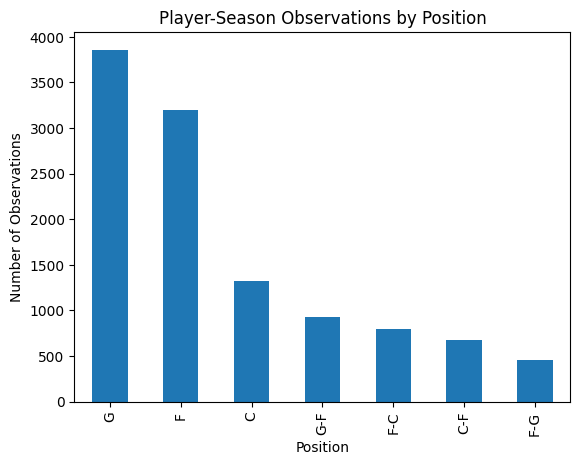

In [7]:
# Create a bar chart showing the number of observations for each position
nba_df["POSITION"].value_counts().plot(kind="bar")

plt.title("Player-Season Observations by Position")
plt.xlabel("Position")
plt.ylabel("Number of Observations")
plt.show()

In [8]:
# Summarize the numerical variables using descriptive statistics
nba_df.describe()

,NBA_ID,AGE,MIN_PER_GAME,GP_TOTAL,PTS_PER12,FGM_PER12,FGA_PER12,FG2M_PER12,FG2A_PER12,FG3M_PER12,...,FG2_PCT,FG3_PCT,FT_PCT,EFG_PCT,THREE_POINT_ATTEMPT_SHARE,FREE_THROW_ATTEMPT_RATE,AST_TO_TOV,OREB_SHARE,DD2_PER_GAME,TD3_PER_GAME
count,1.124200e+04,11242.000000,11242.000000,11242.000000,11242.000000,11242.000000,11242.000000,11242.000000,11242.000000,11242.000000,...,11240.000000,9244.000000,11219.000000,11242.000000,11242.000000,11242.000000,11239.000000,11242.000000,11242.000000,11242.000000
mean,3.196985e+05,27.168831,21.988066,61.218822,4.588848,1.719087,3.863309,1.371407,2.857887,0.347680,...,0.478161,0.301384,0.737191,0.489547,0.252178,0.289653,1.528083,0.252609,0.072675,0.002033
std,5.689384e+05,4.336356,9.221160,22.576383,1.465374,0.534343,1.090536,0.565654,1.078511,0.324941,...,0.072893,0.139036,0.129601,0.064315,0.213280,0.149027,0.882189,0.101931,0.136504,0.015375
min,2.000000e+00,18.000000,2.893023,4.000000,0.470588,0.164384,0.499411,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.133333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.710000e+03,24.000000,14.302273,45.000000,3.575642,1.344828,3.101510,0.964797,2.091743,0.000000,...,0.436568,0.272727,0.666667,0.452830,0.026438,0.186464,0.904762,0.173913,0.000000,0.000000
50%,1.011060e+05,27.000000,21.366081,65.000000,4.447991,1.673469,3.795140,1.323284,2.784084,0.314851,...,0.475212,0.333333,0.750000,0.489796,0.246955,0.264151,1.398936,0.250000,0.013889,0.000000
75%,2.030800e+05,30.000000,29.674004,80.000000,5.430626,2.047054,4.548593,1.720275,3.547462,0.583734,...,0.517857,0.377766,0.821773,0.527192,0.414634,0.363636,2.000000,0.327721,0.075949,0.000000
max,1.641645e+06,43.000000,43.561538,107.000000,11.520728,4.251232,8.392112,3.913710,7.310345,1.894737,...,1.000000,1.000000,1.000000,0.800000,1.000000,1.500000,16.000000,0.666667,1.000000,0.571429


The average player age is 27.17 years, with ages ranging from 18 to 43. Players averaged 21.99 minutes per game, 61.22 games played, and 4.59 points per 12 minutes.

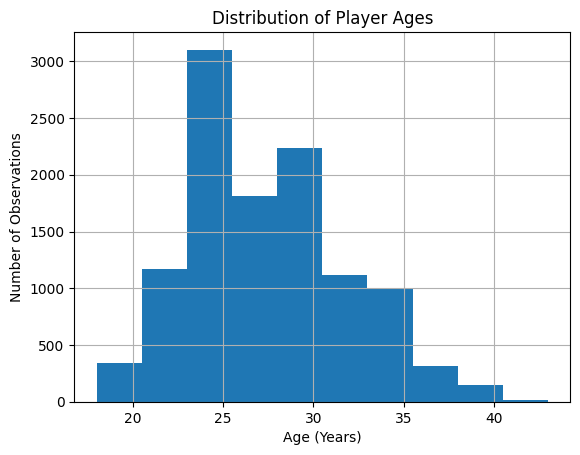

In [9]:
# Create a histogram to examine the distribution of player ages
nba_df["AGE"].hist()

plt.title("Distribution of Player Ages")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Observations")
plt.show()

Most player-season observations are between 23 and 30 years old, with the highest concentration around ages 23–25. There are fewer observations for players under 20 or over 35.

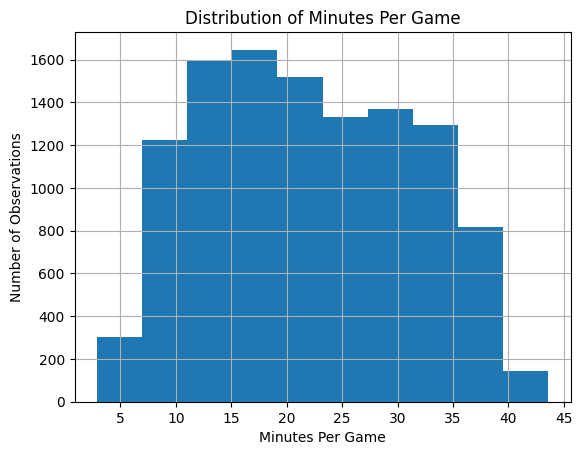

In [10]:
# Create a histogram to examine the distribution of minutes played per game
nba_df["MIN_PER_GAME"].hist()

plt.title("Distribution of Minutes Per Game")
plt.xlabel("Minutes Per Game")
plt.ylabel("Number of Observations")
plt.show()

Most player-season observations fall between 10 and 35 minutes per game, with the highest concentration around 15–20 minutes. There are fewer observations below 5 or above 40 minutes per game.

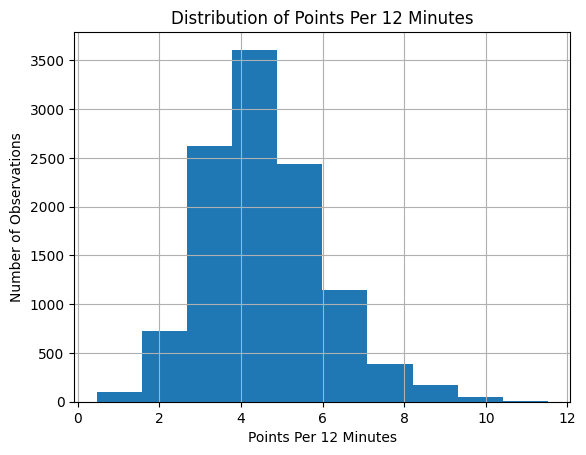

In [11]:
# Create a histogram to examine the distribution of points per 12 minutes
nba_df["PTS_PER12"].hist()

plt.title("Distribution of Points Per 12 Minutes")
plt.xlabel("Points Per 12 Minutes")
plt.ylabel("Number of Observations")
plt.show()

Most observations fall between 3 and 6 points per 12 minutes, with the highest concentration around 4–5 points. There are fewer observations above 8 points.

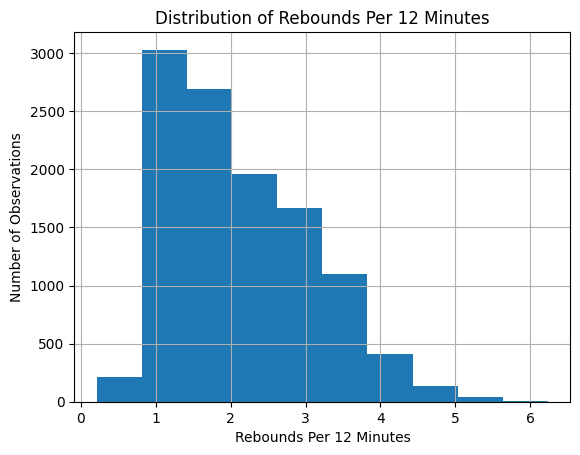

In [12]:
# Create a histogram to examine the distribution of rebounds per 12 minutes
nba_df["REB_PER12"].hist()

plt.title("Distribution of Rebounds Per 12 Minutes")
plt.xlabel("Rebounds Per 12 Minutes")
plt.ylabel("Number of Observations")
plt.show()

Most observations fall between 1 and 3 rebounds per 12 minutes, with the highest concentration around 1–1.5 rebounds. There are fewer observations above 4 rebounds.

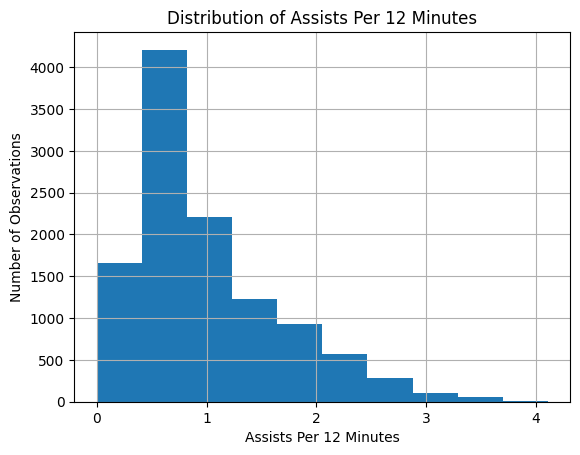

In [13]:
# Create a histogram to examine the distribution of assists per 12 minutes
nba_df["AST_PER12"].hist()

plt.title("Distribution of Assists Per 12 Minutes")
plt.xlabel("Assists Per 12 Minutes")
plt.ylabel("Number of Observations")
plt.show()

Most observations fall between 0 and 1.5 assists per 12 minutes, with the highest concentration around 0.5–0.8 assists. There are fewer observations above 2 assists.

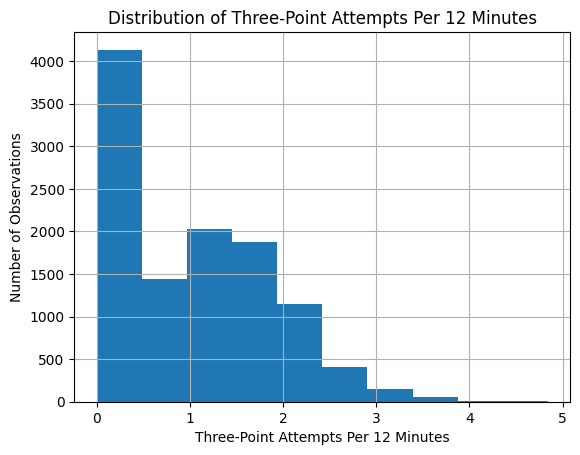

In [14]:
# Create a histogram to examine the distribution of three-point attempts per 12 minutes
nba_df["FG3A_PER12"].hist()

plt.title("Distribution of Three-Point Attempts Per 12 Minutes")
plt.xlabel("Three-Point Attempts Per 12 Minutes")
plt.ylabel("Number of Observations")
plt.show()


Most observations fall between 0 and 2 three-point attempts per 12 minutes, with the highest concentration around 0–0.5 attempts. There are fewer observations above 3 attempts.

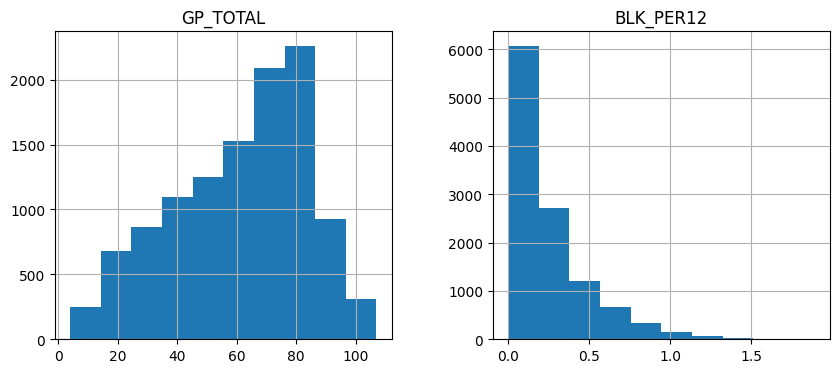

In [15]:
# Examine the distributions of games played and blocks per 12 minutes
nba_df[["GP_TOTAL", "BLK_PER12"]].hist(figsize=(10, 4))
plt.show()

Most player-season observations have between 40 and 85 games played, with the highest concetration around 75-85 games. Blocks per 12 minutes are heavily right-skewed, with most observations below 0.5 blocks and fewer observations above 1. These distributions show that games played varies across players while high block averages are relatively uncommon.

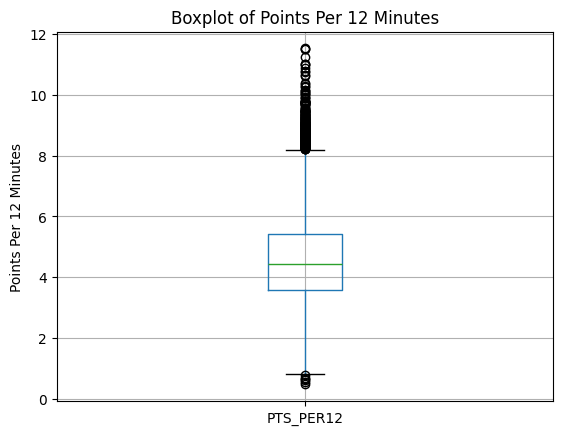

In [16]:
# Create a boxplot to examine the spread and potential outliers in points per 12 minutes
nba_df.boxplot(column="PTS_PER12")

plt.title("Boxplot of Points Per 12 Minutes")
plt.ylabel("Points Per 12 Minutes")
plt.show()

The median is around 4.5 points per 12 minutes, with most observations falling between 3.6 and 5.5. There are several outliers above 8 points and a few below 1 point per 12 minutes.

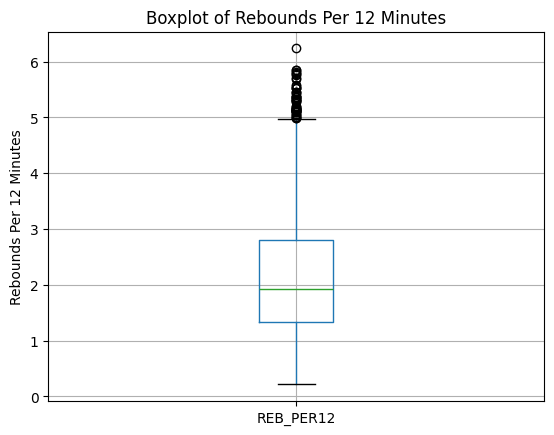

In [17]:
# Create a boxplot to examine the spread and potential outliers in rebounds per 12 minutes
nba_df.boxplot(column="REB_PER12")

plt.title("Boxplot of Rebounds Per 12 Minutes")
plt.ylabel("Rebounds Per 12 Minutes")
plt.show()

The median is around 1.9 rebounds per 12 minutues, with the middle 50% of observations falling between approximately 1.3 and 2,8 rebounds. There are several outliers above 5 rebounds per 12 minutes, with the highest reaching around 6.2.

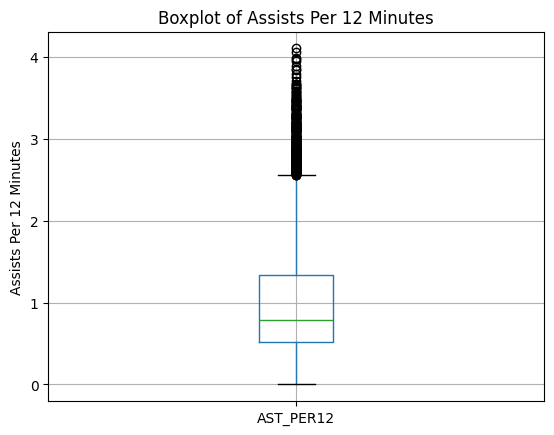

In [18]:
# Create a boxplot to examine the spread and potential outliers in assists per 12 minutes
nba_df.boxplot(column="AST_PER12")

plt.title("Boxplot of Assists Per 12 Minutes")
plt.ylabel("Assists Per 12 Minutes")
plt.show()

The median is around 0.8 assists per 12 minutes, with the middle 50% of observations falling between approximately 0.5 and 1.3 assists. There are several outliers above 2.5 assists, with the highest reaching around 4.1.

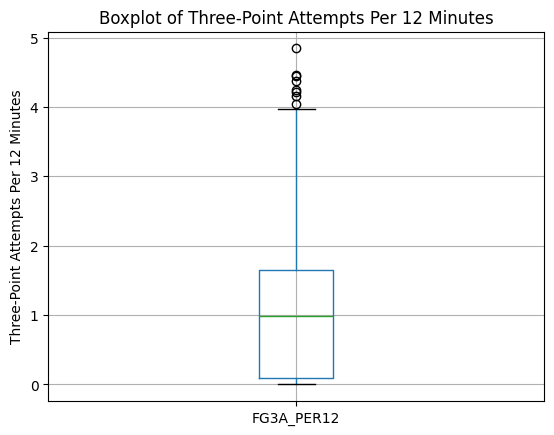

In [19]:
# Create a boxplot to examine the spread and potential outliers in three-point attempts per 12 minutes
nba_df.boxplot(column="FG3A_PER12")

plt.title("Boxplot of Three-Point Attempts Per 12 Minutes")
plt.ylabel("Three-Point Attempts Per 12 Minutes")
plt.show()


The median is around 1 three-point attempt per 12 minutes, with the middle 50% of observations falling between approximatley 0.1 and 1.6 attempts. There are a few outliers above 4 attempts, with the highest reaching around 4.9.

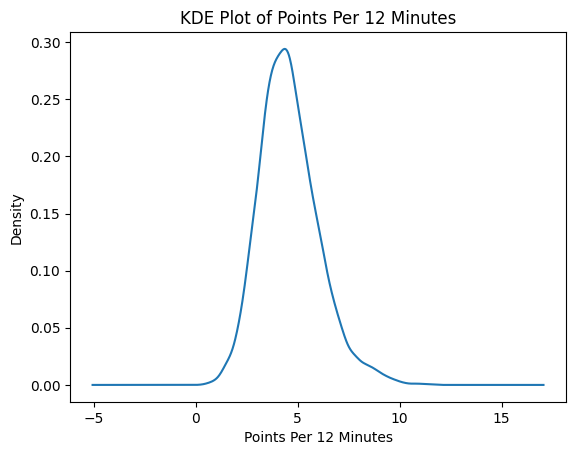

In [20]:
# Create a KDE plot to examine the distribution of points per 12 minutes
nba_df["PTS_PER12"].plot.kde()

plt.title("KDE Plot of Points Per 12 Minutes")
plt.xlabel("Points Per 12 Minutes")
plt.ylabel("Density")
plt.show()

The distribution peaks around 4-5 points per 12 minutes, with most observations concentrated between approximatley 3 and 6 points. The cureve has a longer tail toward higher scoring values, showing the higher scoring observations are less common.

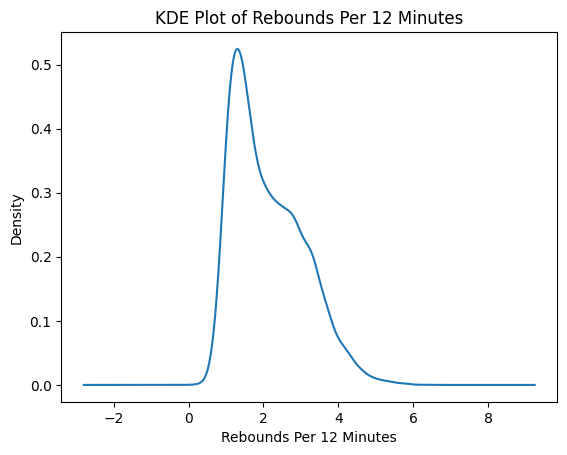

In [21]:
# Create a KDE plot to examine the distribution of rebounds per 12 minutes
nba_df["REB_PER12"].plot.kde()

plt.title("KDE Plot of Rebounds Per 12 Minutes")
plt.xlabel("Rebounds Per 12 Minutes")
plt.ylabel("Density")
plt.show()

The distribution peaks around 1.3 rebounds per 12 minutes, with most observations concentrated between approximatley 1 and 3.5 rebounds. The curve is right-skewed, meaning higher rebound values are less common.

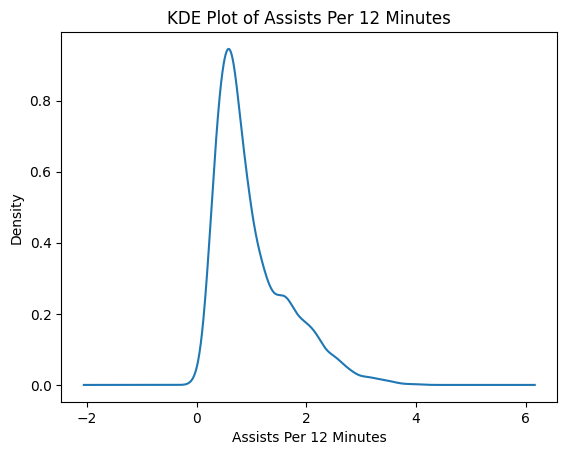

In [22]:
# Create a KDE plot to examine the distribution of assists per 12 minutes
nba_df["AST_PER12"].plot.kde()

plt.title("KDE Plot of Assists Per 12 Minutes")
plt.xlabel("Assists Per 12 Minutes")
plt.ylabel("Density")
plt.show()

The distribution peaks around 0.6 assists per 12 minutes, with most observations concentrated between approximately 0.3 and 1.5 assists. The curve is right-skewed, with fewer observations having higher assist values.

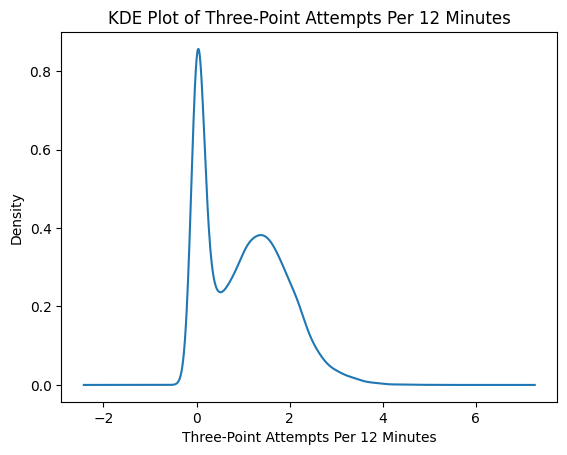

In [23]:
# Create a KDE plot to examine the distribution of three-point attempts per 12 minutes
nba_df["FG3A_PER12"].plot.kde()

plt.title("KDE Plot of Three-Point Attempts Per 12 Minutes")
plt.xlabel("Three-Point Attempts Per 12 Minutes")
plt.ylabel("Density")
plt.show()

The distribution has a sharp peak around 0 three-point attempts per 12 minutes and a second, smaller peak around 1.4 attempts. The curve is right skewed, with fewer observations above 3 attempts.

In [24]:
# Calculate the average points per 12 minutes for each position
nba_df.groupby("POSITION")["PTS_PER12"].mean()

,PTS_PER12
POSITION,
C,4.113066
C-F,4.598663
F,4.620966
F-C,4.519263
F-G,4.556671
G,4.757005
G-F,4.524113


Gaurd (G) have the highest average at approximately 4.76 points per 12 minutes, while centers (C) have the lowest at 4.11. The other positions have similar averages, ranging from about 4.52 to 4.62 points.

In [25]:
# Calculate the average rebounds per 12 minutes for each position
nba_df.groupby("POSITION")["REB_PER12"].mean()

,REB_PER12
POSITION,
C,3.280755
C-F,3.223570
F,2.361415
F-C,3.081870
F-G,1.767422
G,1.310826
G-F,1.663009


Centers (C) have the highest average at approximately 3.28 rebounds per 12 minutes, followed closely by C-F players at 3.22. Guards (G) have the lowest average at 1.31 rebounds. Overall, centers and center-related positions tend to average more rebounds than guards.

In [26]:
# Calculate the average assists per 12 minutes for each positon
nba_df.groupby("POSITION")["AST_PER12"].mean()

,AST_PER12
POSITION,
C,0.504544
C-F,0.658136
F,0.722339
F-C,0.626926
F-G,0.876428
G,1.580007
G-F,0.913046


Gaurds (G) have the highest average at approximately 1.58 assists per 12 minutes, while centers (C) have the lowest at 0.50. The other positions average between 0.63 and 0.91 assists. Overall, gaurds average noticebly more assists than the other postions.

In [27]:
# Calculate the average three-point attempts per 12 minutes for each positon
nba_df.groupby("POSITION")["FG3A_PER12"].mean()

,FG3A_PER12
POSITION,
C,0.119632
C-F,0.338550
F,0.950297
F-C,0.516574
F-G,1.344996
G,1.441055
G-F,1.384454


Gaurds (G) have the highest average at approximately 1.44 three-point attempts per 12 minutes, followed closely by G-F players at 1.38. Centers (C) have the lowest average at 0.12. Overall, gaurds and gaurd-related positions attempt more three-pointers than centers and center-related positions.

In [28]:
# Calculate the average blocks per 12 minutes for each position
nba_df.groupby("POSITION")["BLK_PER12"].mean()

,BLK_PER12
POSITION,
C,0.590334
C-F,0.484098
F,0.249119
F-C,0.401534
F-G,0.180902
G,0.095172
G-F,0.162000


Centers (C) have the highest average at approximately 0.59 blocks per 12 minutes, follwed by C-F players at 0.48. Gaurds (G) have the lowest average at 0.10. Overall, centers and center-related positions average more blocks than gaurds and gaurd-related positions.

In [29]:
# Calculate the average steals per 12 minutes
nba_df.groupby("POSITION")["STL_PER12"].mean()

,STL_PER12
POSITION,
C,0.274033
C-F,0.307043
F,0.359043
F-C,0.321425
F-G,0.396458
G,0.433305
G-F,0.401121


Gaurds (G) have the highest average at approximately 0.43 steals per 12 minutes, followed by G-F players at 0.40. Centers (C)have the lowest average 0.27. Overall, gaurds and faurd related positions average slightly more steals than centers and center related positions.

In [30]:
# Calculate the average field goal percentage for each position
nba_df.groupby("POSITION")["FG_PCT"].mean()

,FG_PCT
POSITION,
C,0.499408
C-F,0.495783
F,0.448134
F-C,0.487990
F-G,0.422654
G,0.416407
G-F,0.426761


Centers (C) have the highest average field goal percentage at approximately 49.94%, followed closely by C-F players at 49.58%. Gaurds (G) have the lowest average at 41.64%. Overall, centers and center-related positions have higher average field goal percentages than gaurds and gaurd-related positions.

In [31]:
# Calculate the average three-point shooting percentage for each position
nba_df.groupby("POSITION")["FG3_PCT"].mean()

,FG3_PCT
POSITION,
C,0.171636
C-F,0.217791
F,0.288998
F-C,0.230312
F-G,0.320367
G,0.332707
G-F,0.329261


Gaurds (G) have the highest average three-point shooting percentage at approximately 33.27%, followed by G-F players at 32.93%. Centers (C) have the lowest average at 17.16%. Overall, gaurds and gaurd-related positions have higher average three-point shooting percentages than centers and center-related positions.

In [32]:
# Calculate the average free throw percentage for each position
nba_df.groupby("POSITION")["FT_PCT"].mean()

,FT_PCT
POSITION,
C,0.639541
C-F,0.693387
F,0.728110
F-C,0.697516
F-G,0.749780
G,0.787766
G-F,0.757235


Gaurds (G) have the highest average free throw percentage at approximately 78.78%, followed by G-F players at 75.72%. Centers (C) have the lowest average at 63.95%. Overall, gaurds and gaurd-related positions tend to have higher free throw percentages than centers and center-related positions.

In [33]:
# Calculate the average minutes played per game for each position
nba_df.groupby("POSITION")["MIN_PER_GAME"].mean()

,MIN_PER_GAME
POSITION,
C,19.296121
C-F,22.030935
F,21.987707
F-C,20.797239
F-G,23.062860
G,22.846911
G-F,22.714311


F-G players have the highest average at approximately 23.06 minutes per game, followed by gaurds (G) at 22.85. Centers (C) have the lowest average at 19.30 minutes. Overall, most positions average between 20 and 23 mintues per game.

In [34]:
# Calculate the average number of games played for each position
nba_df.groupby("POSITION")["GP_TOTAL"].mean()

,GP_TOTAL
POSITION,
C,59.280303
C-F,63.240768
F,60.833490
F-C,62.695000
F-G,61.713024
G,61.112176
G-F,62.755102


In [35]:
# Compare the remaining player statistics across positions
nba_df.groupby("POSITION")[["AGE", "TOV_PER12", "OREB_PER12", "DREB_PER12", "FG2_PCT", "EFG_PCT", "AST_TO_TOV"]].mean()

,AGE,TOV_PER12,OREB_PER12,DREB_PER12,FG2_PCT,EFG_PCT,AST_TO_TOV
POSITION,,,,,,,
C,27.343939,0.681622,1.097036,2.183804,0.505877,0.503677,0.775311
C-F,27.997046,0.672985,1.023374,2.201545,0.510809,0.509589,1.059680
F,26.995626,0.616555,0.673372,1.688588,0.484053,0.489928,1.248407
F-C,27.162500,0.631504,0.989136,2.092917,0.512092,0.509089,1.039353
F-G,26.671082,0.624293,0.398679,1.367684,0.468163,0.480031,1.466849
G,27.125648,0.747100,0.256857,1.055697,0.453940,0.477635,2.179520
G-F,27.340494,0.581079,0.364797,1.299764,0.470970,0.490855,1.646387


Canters and center-related positions have higher offensive and defensive rebounding averages, while gaurds have the lowest. Gaurds also have the highest average assist-to-turnover ration at approximately 2.18, compared to 0.78 for centers. Centers and center-related positions generally have higher two-point and effective field goal percentages. Age and turnovers show smaller differences across positions. Overall, rebounding and assists-to-turnover ratio appear to be useful features for distinguishing player positions.  

In [36]:
# Calculate correlations between basketball performance statistics
nba_df.drop(columns=["NBA_ID", "PLAYER_NAME", "SEASON", "POSITION"]).corr()

,AGE,MIN_PER_GAME,GP_TOTAL,PTS_PER12,FGM_PER12,FGA_PER12,FG2M_PER12,FG2A_PER12,FG3M_PER12,FG3A_PER12,...,FG2_PCT,FG3_PCT,FT_PCT,EFG_PCT,THREE_POINT_ATTEMPT_SHARE,FREE_THROW_ATTEMPT_RATE,AST_TO_TOV,OREB_SHARE,DD2_PER_GAME,TD3_PER_GAME
AGE,1.000000,0.048920,0.054492,-0.124195,-0.136893,-0.137072,-0.144794,-0.139737,0.026946,0.001417,...,-0.064954,0.052077,0.086836,0.001158,0.046275,-0.068686,0.147429,-0.121244,-0.015621,0.007761
MIN_PER_GAME,0.048920,1.000000,0.521522,0.533929,0.503001,0.450036,0.379693,0.352558,0.166185,0.127773,...,0.154346,0.121224,0.256280,0.227263,0.015388,0.039576,0.159837,-0.219445,0.541184,0.183545
GP_TOTAL,0.054492,0.521522,1.000000,0.237786,0.229952,0.133716,0.173748,0.117140,0.075681,0.022523,...,0.189402,0.096907,0.151369,0.273839,-0.007008,0.026452,0.063559,-0.077497,0.249660,0.082921
PTS_PER12,-0.124195,0.533929,0.237786,1.000000,0.957883,0.909758,0.704358,0.659485,0.349031,0.324640,...,0.254370,0.158839,0.332781,0.327877,0.061280,0.078894,-0.005528,-0.193237,0.435698,0.207275
FGM_PER12,-0.136893,0.503001,0.229952,0.957883,1.000000,0.897139,0.826956,0.762449,0.204873,0.180376,...,0.334460,0.079044,0.228560,0.360818,-0.081805,-0.007929,-0.053735,-0.100094,0.464586,0.192044
FGA_PER12,-0.137072,0.450036,0.133716,0.909758,0.897139,1.000000,0.620602,0.681870,0.394943,0.410485,...,-0.020709,0.128597,0.324187,0.023608,0.134071,-0.174500,0.051852,-0.262206,0.320983,0.178647
FG2M_PER12,-0.144794,0.379693,0.173748,0.704358,0.826956,0.620602,1.000000,0.940078,-0.380920,-0.389638,...,0.368690,-0.238223,-0.010109,0.209580,-0.593570,0.262188,-0.238884,0.246474,0.533652,0.153816
FG2A_PER12,-0.139737,0.352558,0.117140,0.659485,0.762449,0.681870,0.940078,1.000000,-0.382686,-0.387108,...,0.061936,-0.232967,0.021454,-0.076646,-0.606106,0.213671,-0.223286,0.219104,0.468896,0.136281
FG3M_PER12,0.026946,0.166185,0.075681,0.349031,0.204873,0.394943,-0.380920,-0.382686,1.000000,0.974895,...,-0.091712,0.572821,0.393143,0.228505,0.898759,-0.469453,0.327555,-0.593657,-0.164998,0.048041
FG3A_PER12,0.001417,0.127773,0.022523,0.324640,0.180376,0.410485,-0.389638,-0.387108,0.974895,1.000000,...,-0.103307,0.486648,0.382040,0.125307,0.924582,-0.486327,0.343845,-0.603653,-0.179930,0.055298


Several player statistics have strong positive correlations. Points per 12 minutes and field goals made per 12 minutes have a correlation of approximately 0.96, while three-point field goals made and attempted have a correlation of approximately 0.97. Two-point field goals made and attempted are also strongly correlated at 0.94. These results suggest that some features contain similar information, which could be important when selecting variables for our prediction model.

In [37]:
# Examine correlations among key scoring, rebounding, passing, and defensive statistics
nba_df[["PTS_PER12", "FGM_PER12", "FG3A_PER12", "REB_PER12", "OREB_PER12", "AST_PER12", "STL_PER12", "BLK_PER12"]].corr()

,PTS_PER12,FGM_PER12,FG3A_PER12,REB_PER12,OREB_PER12,AST_PER12,STL_PER12,BLK_PER12
PTS_PER12,1.000000,0.957883,0.324640,0.001044,-0.121683,0.238550,0.004584,-0.072900
FGM_PER12,0.957883,1.000000,0.180376,0.101909,-0.011326,0.183238,-0.022334,0.010754
FG3A_PER12,0.324640,0.180376,1.000000,-0.526609,-0.646359,0.260629,0.092339,-0.439252
REB_PER12,0.001044,0.101909,-0.526609,1.000000,0.881999,-0.448806,-0.222677,0.635169
OREB_PER12,-0.121683,-0.011326,-0.646359,0.881999,1.000000,-0.500378,-0.202107,0.607265
AST_PER12,0.238550,0.183238,0.260629,-0.448806,-0.500378,1.000000,0.382275,-0.411418
STL_PER12,0.004584,-0.022334,0.092339,-0.222677,-0.202107,0.382275,1.000000,-0.192683
BLK_PER12,-0.072900,0.010754,-0.439252,0.635169,0.607265,-0.411418,-0.192683,1.000000


Points scored and field goals made per 12 minutes have a very strong positive correlation (0.96). Total rebounds and offensive rebounds are also strongly correlated (0.88). Three-point attempts have a negative correlation with rebounds (-0.53) and offensive rebounds (-0.65), while rebounds and blocks have a positive correlation (0.64). These patterns suggest that scoring, rebounding, and shooting statistics may provide useful information for distinguishing player positions, although some features overlap

In [38]:
# Compare additional shooting and defensive statistics across player positions
nba_df.groupby("POSITION")[["FG2A_PER12", "FG3M_PER12", "FTA_PER12", "BLKA_PER12", "PF_PER12", "THREE_POINT_ATTEMPT_SHARE", "FREE_THROW_ATTEMPT_RATE", "OREB_SHARE"]].mean()

,FG2A_PER12,FG3M_PER12,FTA_PER12,BLKA_PER12,PF_PER12,THREE_POINT_ATTEMPT_SHARE,FREE_THROW_ATTEMPT_RATE,OREB_SHARE
POSITION,,,,,,,,
C,3.160451,0.036821,1.246461,0.276306,1.595338,0.028303,0.402009,0.336679
C-F,3.318894,0.112782,1.268244,0.267279,1.428560,0.083359,0.358740,0.314551
F,2.921787,0.323911,1.121284,0.253775,1.183618,0.246725,0.291784,0.276052
F-C,3.087831,0.172705,1.216065,0.262591,1.425071,0.127322,0.351612,0.318487
F-G,2.601206,0.454987,1.010758,0.217320,1.048411,0.340837,0.253105,0.224176
G,2.687818,0.504421,1.004409,0.227828,0.956583,0.351279,0.242224,0.192344
G-F,2.506393,0.489244,0.924081,0.208583,1.017741,0.364368,0.233972,0.214854


Gaurds and gaurd-related postions have higher three-point shooting averages and attempt shares, while centers and center-related positions have higher free throw attempt rates, offensive rebounding shares, and personal fouls per 12 minutes. Centers have the lowest three-point attempt share at approximately 2.83%, compared to 35.13% for guards. These differences suggest that shooting preferences and rebounding statistics could be useful for predicting player positions.

In [39]:
# Compare the remaining scoring, shooting, foul, and double-double statistics by position
nba_df.groupby("POSITION")[["FGA_PER12", "FG2M_PER12", "FTM_PER12", "PFD_PER12", "DD2_PER_GAME", "TD3_PER_GAME"]].mean()

,FGA_PER12,FG2M_PER12,FTM_PER12,PFD_PER12,DD2_PER_GAME,TD3_PER_GAME
POSITION,,,,,,
C,3.280082,1.598188,0.805976,1.121178,0.129910,0.001580
C-F,3.657444,1.692414,0.876566,1.136295,0.164280,0.001353
F,3.872085,1.415055,0.820199,0.921683,0.073520,0.001656
F-C,3.604404,1.574364,0.854622,1.098383,0.115715,0.001114
F-G,3.946203,1.214446,0.765782,0.818190,0.033980,0.002951
G,4.128873,1.224574,0.797136,0.909097,0.042711,0.002879
G-F,3.890847,1.177128,0.705442,0.770198,0.028077,0.001306


Gaurds have the highest average field goal attempts per 12 minutes (4.13), while centers and center-related postions generally have higher two-point field goals made and double-doubles per game. Centers also tend to draw more fouls than gaurds. Triple-doubles are extremely uncommon across all positions, so they may not be useful for distinguishing player positions. Overall, these results show additional differences in playing styles across positions.

In [40]:
# Count nonmissing values in key statistics for each player position
nba_df.groupby("POSITION")[["PFD_PER12", "FG3_PCT", "FT_PCT", "AST_TO_TOV", "FG2_PCT"]].count()

,PFD_PER12,FG3_PCT,FT_PCT,AST_TO_TOV,FG2_PCT
POSITION,,,,,
C,814,387,1318,1320,1320
C-F,441,415,677,677,677
F,2233,2743,3193,3200,3200
F-C,563,498,800,800,800
F-G,320,442,451,453,453
G,2724,3834,3852,3860,3859
G-F,671,925,928,929,931


The results show that some statistics have more missing values than others. Fouls drawn per 12 minutes (PFD_PER12) has missing values across every position, while three-point percantage (FG3_PCT) is especially incomplete for centers. Most other statistics have very few missing values. This is important because missing data could affect our prediction model, especially if certain postions are more affected than others.

In [41]:
# Count missing values for each player position
nba_df[["PFD_PER12", "FG3_PCT", "FT_PCT", "AST_TO_TOV", "FG2_PCT"]].isnull().groupby(nba_df["POSITION"]).sum()

,PFD_PER12,FG3_PCT,FT_PCT,AST_TO_TOV,FG2_PCT
POSITION,,,,,
C,506,933,2,0,0
C-F,236,262,0,0,0
F,968,458,8,1,1
F-C,237,302,0,0,0
F-G,133,11,2,0,0
G,1136,26,8,0,1
G-F,260,6,3,2,0


Fouls drawn per 12 mintues (PFD_PER12) has a large number of missing values across all positions, especially gaurds (1,136) and forwards (968). Three-point percentage (FG3_PCT) has the most missing values among centers (933), which may be related to centers attempting fewer three-point shots. Most other statistics have very few missing values. These differences are important to consider before building our prediction model.

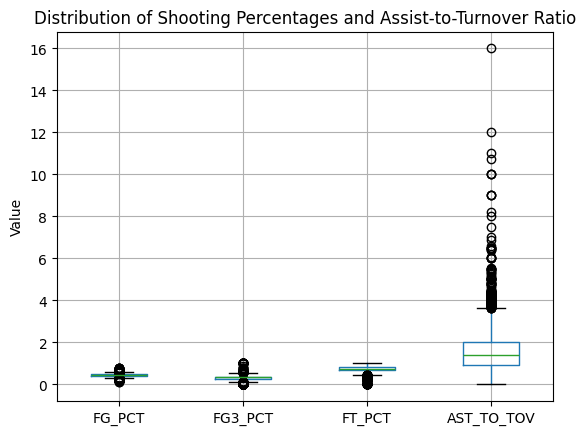

In [42]:
# Examine the distribution and possible outliers in additional player statistics
nba_df.boxplot(column=["FG_PCT", "FG3_PCT", "FT_PCT", "AST_TO_TOV"])
plt.title("Distribution of Shooting Percentages and Assist-to-Turnover Ratio")
plt.ylabel("Value")
plt.show()

The boxplot shows that the assist-to-turnover ratio has several high outliers, with some value reaching 16. The shooting percentages have much smaller ranges, although they also contain some outliers. These results suggest that certain players have unusually high assist-to-turnover ratios, which may need to be considered when building our prediction model.

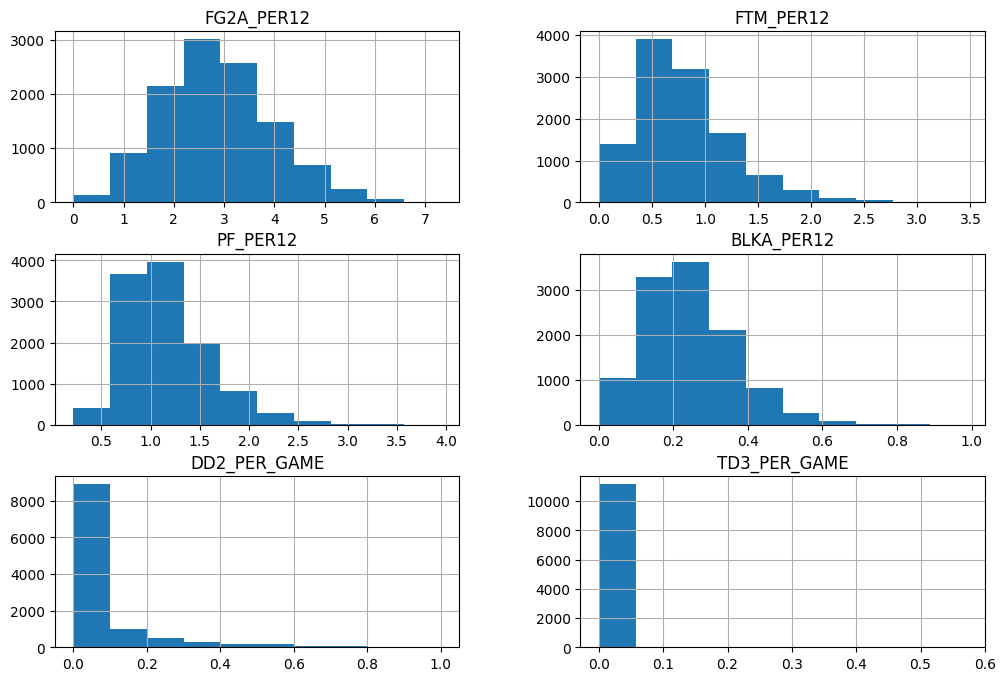

In [43]:
# Examine distributions of additional player statistics to identify skewness and unusual values
nba_df[["FG2A_PER12", "FTM_PER12", "PF_PER12", "BLKA_PER12", "DD2_PER_GAME", "TD3_PER_GAME"]].hist(figsize=(12, 8))
plt.show()

Two-point field goal attempts are fairly evenly distributed around the middle, while free throws made, personal fouls, and blocked shot attempts are more right-skewed. Double-doubles and triple-doubles are heavily concentrated near zero, showing that most players rarely record them. These patterns suggest that some statistics have much more variation than others.

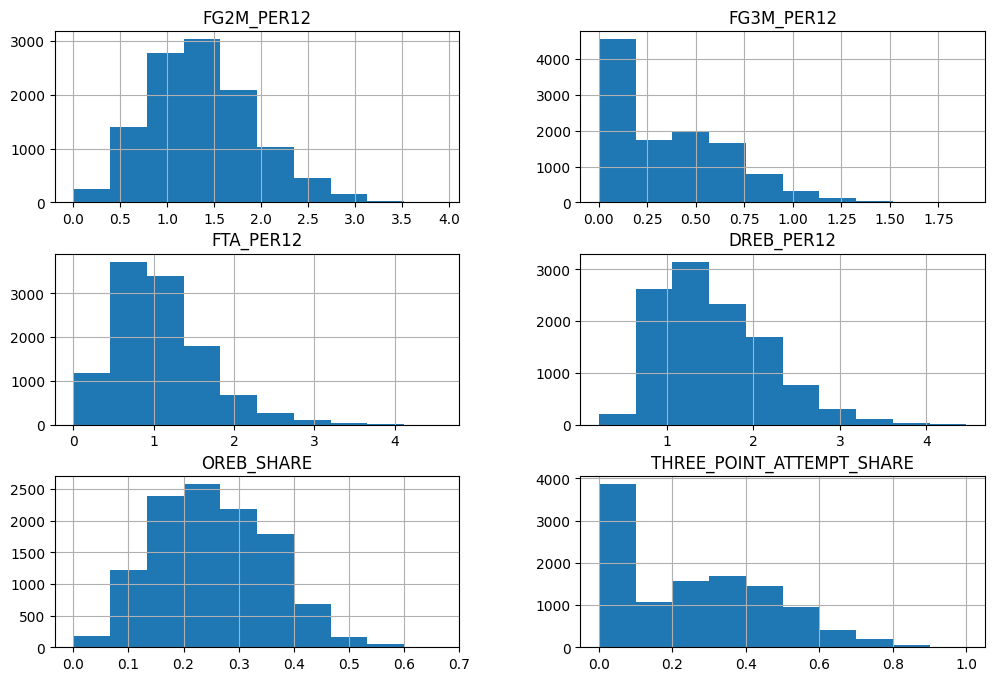

In [44]:
# Examine distributions of additional shooting and rebounding statistics
nba_df[["FG2M_PER12", "FG3M_PER12", "FTA_PER12", "DREB_PER12", "OREB_SHARE", "THREE_POINT_ATTEMPT_SHARE"]].hist(figsize=(12, 8))
plt.show()

Two-point field goals made and defensive rebounds have fairly balanced distributions, while three-point field goals made and free throw attempts are more right-skewed. Three-point attempt share also has a large concentration of players near zero, suggesting that many players attempt very few three-pointers. These differences help show how shooting and rebounding statistics vary across NBA players.

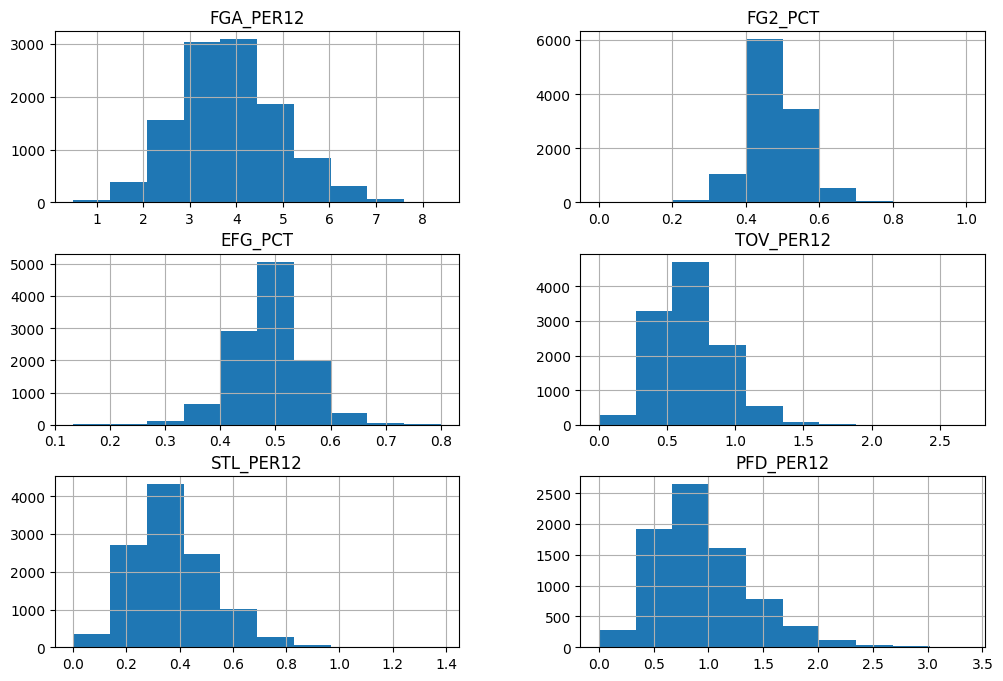

In [45]:
# Examine distributions of remaining shooting, passing, and defensive statistics
nba_df[["FGA_PER12", "FG2_PCT", "EFG_PCT", "TOV_PER12", "STL_PER12", "PFD_PER12"]].hist(figsize=(12, 8))
plt.show()

Field goal attempts, two-point field goal percentage, and effective firld goal percentage fairly concentrated around their middle values. Turnovers, steals, and fouls drawn per 12 minutes are more right-skewed, with a smaller number of players having unusually high values. Overall, these distributions show some variation across players, but no obvious extreme values that would immediately require removal.

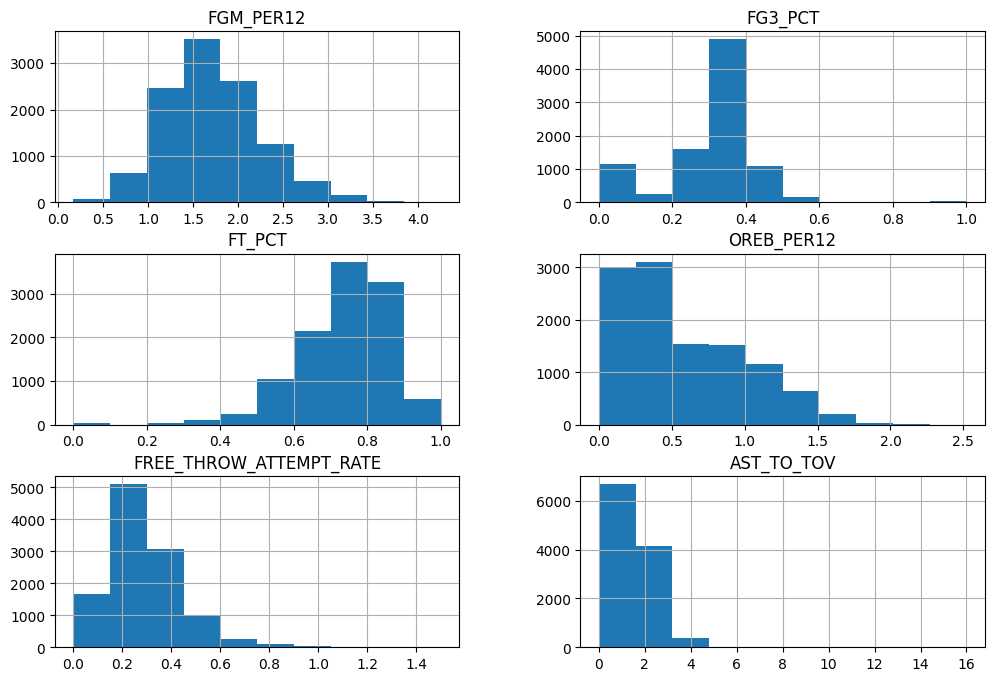

In [46]:
# Examine distributions of the remaining numerical player statistics
nba_df[["FGM_PER12", "FG3_PCT", "FT_PCT", "OREB_PER12", "FREE_THROW_ATTEMPT_RATE", "AST_TO_TOV"]].hist(figsize=(12, 8))
plt.show()

Field goals made are fairley evenly distributed around the middle, while offensive rebounds and free throw attempt rates are more right-skewed. Free throw percentages are concentratred toward higher values, and three-point percentages show a noticeable group of players near zero. The assist-to-turnover ratio is heavily right-skewed, with a few unusually high values. These distributions show that some statistics have more extreme values than others.

In [47]:
# Check for duplicate rows
nba_df.duplicated().sum()

np.int64(0)

In [48]:
# Check whether any player has multiple records within the same season
nba_df.duplicated(subset=["NBA_ID", "SEASON"]).sum()

np.int64(0)

# EDA Analysis Summary

Our EDA identified several patters that could help predict NBA player positions. Gaurds generally have higher assists, steals, and three-point shooting averages, while centers have higher rebounds, blocks, and field goal percentages. The dataset also has some class imbalance, with gaurds and forwards appearing more frequently than hybrid positions.

Several features are strongly correlated, especially scoring and shooting statistics, suggesting that some variables contain overlapping information. We also identified missing values in certain statistics, particularly fould drawn and three-point percentage, along with some outliers in the assist-to-turnover ratio. Finally, the dataset contains no duplicate rows or player-season record.

Overall, these findings suggest that shooting, rebounding, passing, and defensive statistics may be useful for predicting player positions. Missing values, class imbalance, and correlated features should be considered during the modeling stage.